In [9]:
modules = ["pandas","missingno", "seaborn", "matplotlib"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho!")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
missingno  encontrado
seaborn  encontrado
matplotlib  encontrado
¡Terminado!


In [10]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
path = r'../../data/merged_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open,high,low,close,volume,var_diaria,rango_dia,RSI,SMA_50,...,mDEMA_50,mDEMA_200,mDvolatilidad_50,mDvolatilidad_200,mDmomentum_50,mDmomentum_200,fear_greed_index_fg,market_cap_coingecko,bitcoin_gtrends,hashrate_hashrate
0,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,37.0,NaN,NaN,NaN
1,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,39.0,NaN,NaN,9.671772e+07
2,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,38.0,NaN,NaN,NaN
3,2020-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,38.0,NaN,NaN,NaN
4,2020-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,39.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1882,2025-02-25,91494.995,92540.69,86008.23,89604.445623,4.553970e+10,-3.754111,3495.058741,32.799338,98666.606124,...,97116.286177,85680.470277,3931.918837,17668.695896,-13640.40,27768.25,25.0,1.814177e+12,NaN,NaN
1883,2025-02-26,88659.640,89414.15,82131.90,85784.293112,9.674245e+10,-4.263352,3820.152511,25.391866,98404.824672,...,96606.843582,85664.997936,4421.450296,17608.177665,-12774.65,23240.55,21.0,1.759750e+12,NaN,NaN
1884,2025-02-27,84250.090,87078.46,82716.49,84304.347483,6.927743e+10,-1.725194,1479.945629,20.234601,98170.784533,...,96105.614422,85646.694474,4846.191090,17532.553306,-11115.30,25210.20,10.0,1.664315e+12,NaN,NaN
1885,2025-02-27,84250.090,87078.46,82716.49,84281.361471,3.155619e+11,-0.027266,22.986012,20.785375,98059.158818,...,96105.614422,85646.694474,4846.191090,17532.553306,-11115.30,25210.20,10.0,1.663078e+12,NaN,NaN


## 1. Descripción general

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1887 entries, 0 to 1886
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             1887 non-null   object 
 1   open                  1001 non-null   float64
 2   high                  1001 non-null   float64
 3   low                   1001 non-null   float64
 4   close                 1001 non-null   float64
 5   volume                366 non-null    float64
 6   var_diaria            1000 non-null   float64
 7   rango_dia             1000 non-null   float64
 8   RSI                   988 non-null    float64
 9   SMA_50                952 non-null    float64
 10  SMA_200               802 non-null    float64
 11  EMA_50                1001 non-null   float64
 12  EMA_200               1001 non-null   float64
 13  volatilidad_50        952 non-null    float64
 14  volatilidad_200       802 non-null    float64
 15  momentum_50          

In [6]:
df.describe()

,open,high,low,close,volume,var_diaria,rango_dia,RSI,SMA_50,SMA_200,...,mDEMA_50,mDEMA_200,mDvolatilidad_50,mDvolatilidad_200,mDmomentum_50,mDmomentum_200,fear_greed_index_fg,market_cap_coingecko,bitcoin_gtrends,hashrate_hashrate
count,1001.000000,1001.000000,1001.000000,1001.000000,3.660000e+02,1000.000000,1000.000000,988.000000,952.000000,802.000000,...,1097.000000,1097.000000,1048.000000,898.000000,1047.000000,897.000000,1885.000000,3.660000e+02,262.000000,4.710000e+02
mean,44159.058387,45546.621691,42804.564136,44366.542991,4.310259e+10,0.128196,691.016004,52.686423,44372.051890,43413.398214,...,42919.496637,40239.113805,3153.956893,6801.548276,2656.454489,11634.386065,50.496021,1.466621e+12,29.625954,3.144908e+08
std,24794.742052,25913.957388,23686.865379,24997.351788,3.119742e+10,2.447219,792.624615,16.394643,24591.761150,20255.137655,...,22561.948905,17446.980110,2369.042051,4474.450649,9892.083417,17218.171834,22.477132,3.122380e+11,14.980875,2.110355e+08
min,15781.290000,16315.000000,15476.000000,15781.290000,6.340607e+09,-15.379839,0.110000,6.289216,16782.697600,19514.264250,...,17104.484021,20880.578336,338.852772,1593.075003,-19642.250000,-28380.800000,6.000000,1.064889e+12,12.000000,8.165858e+07
25%,23554.850000,24226.000000,23111.040000,23554.850000,2.409280e+10,-0.927853,150.545000,41.904239,23289.763650,25259.010325,...,25368.011289,26252.530443,1560.150886,3283.604256,-2999.175000,1450.050000,29.000000,1.239200e+12,19.000000,1.435949e+08
50%,30692.440000,31500.000000,30251.000000,30766.510000,3.568853e+10,-0.011501,420.445000,52.273597,30647.241500,33652.045750,...,34318.162707,34260.704594,2901.810303,4743.812877,1256.350000,10181.500000,50.000000,1.332049e+12,24.000000,2.221632e+08
75%,62559.960000,65066.660000,59964.440000,63095.822182,4.921125e+10,1.258446,912.842500,62.439076,63625.563184,63593.115714,...,62000.381853,55420.866707,3865.331127,9831.989821,6489.900000,24026.800000,71.000000,1.848577e+12,36.000000,4.538783e+08
max,104651.700000,109588.000000,101391.570000,104683.249078,3.155619e+11,10.560892,6669.523411,99.426709,99311.283860,81978.371300,...,98911.265333,85680.470277,12685.953714,18011.011776,38227.600000,49534.300000,95.000000,2.100630e+12,100.000000,8.677102e+08


## 2. Conteo de nulos

In [7]:
df.isnull().sum(axis=0)

timestamp                  0
open                     886
high                     886
low                      886
close                    886
volume                  1521
var_diaria               887
rango_dia                887
RSI                      899
SMA_50                   935
SMA_200                 1085
EMA_50                   886
EMA_200                  886
volatilidad_50           935
volatilidad_200         1085
momentum_50              936
momentum_200            1086
mDopen                   790
mDhigh                   790
mDlow                    790
mDclose                  790
mDvolume                 791
mDvar_diaria             790
mDrango_dia              790
mD_RSI                   803
mDSMA_50                 839
mDSMA_200                989
mDEMA_50                 790
mDEMA_200                790
mDvolatilidad_50         839
mDvolatilidad_200        989
mDmomentum_50            840
mDmomentum_200           990
fear_greed_index_fg        2
market_cap_coi

<Axes: >

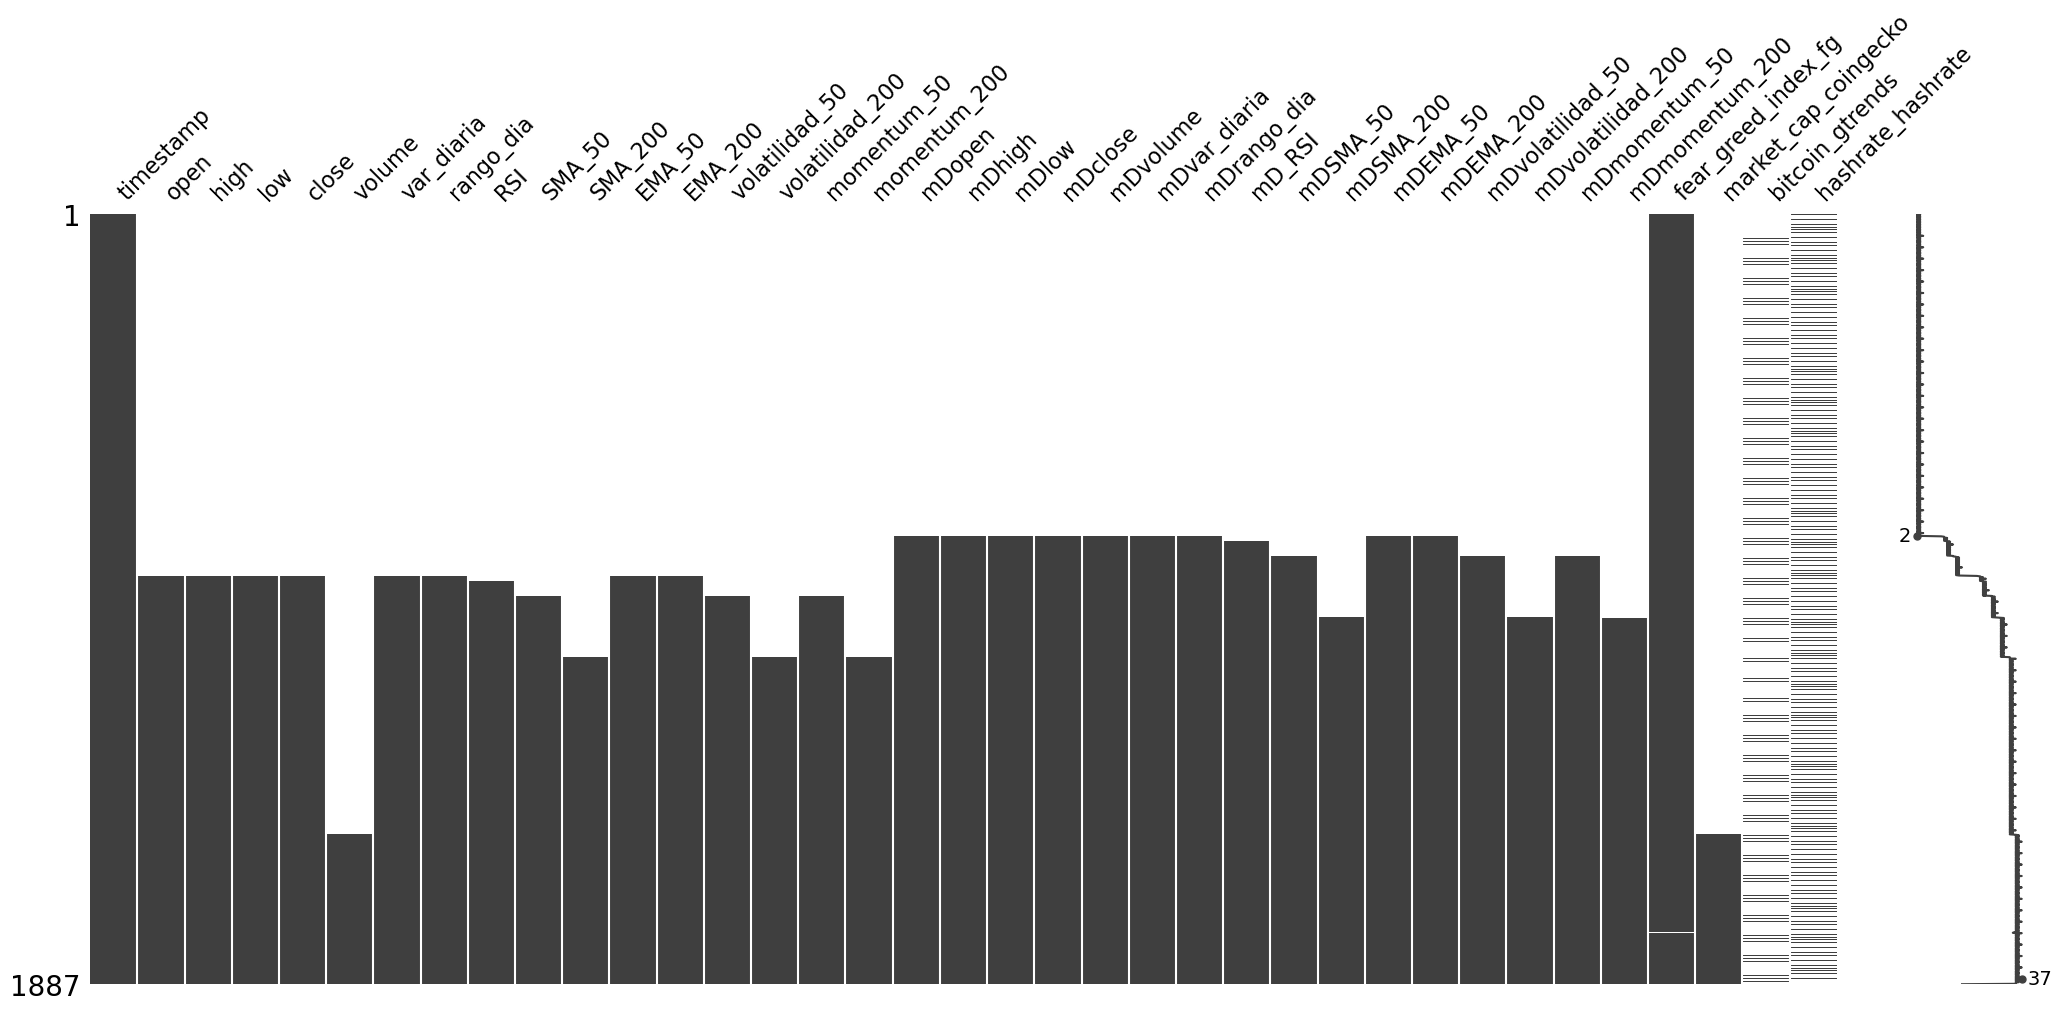

In [8]:
msno.matrix(df)

## 3. Correlaciones

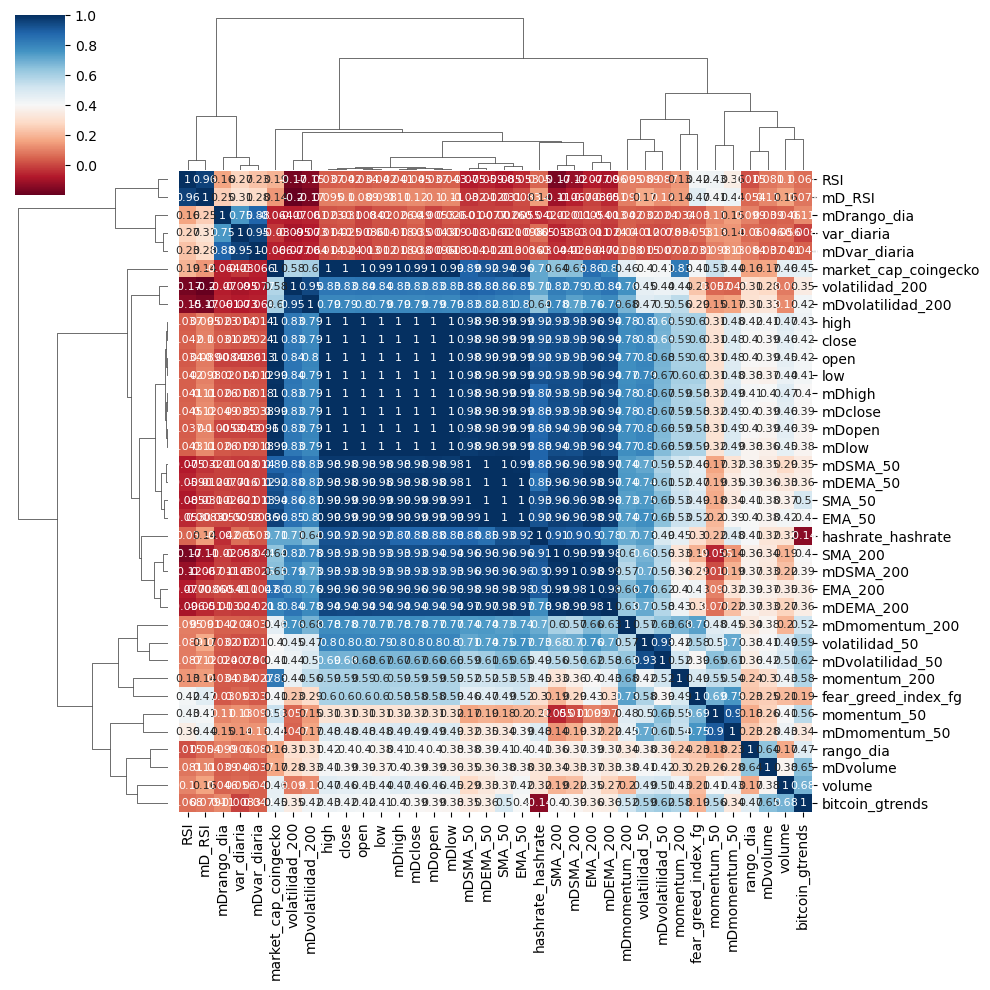

In [11]:
g = sns.clustermap(df.iloc[:, 1:].corr(), 
                   method = 'complete', 
                   cmap   = 'RdBu', 
                   annot  = True, 
                   annot_kws = {'size': 8})